# code_156 · Prompt representations, source examples and retrieval

**Book:** section 30.2. Restart and run all cells using the [dedicated Python 3.12 CPU runtime](../CHAPTER_30_RUNTIME.md), not the earlier chapters' 3.14 environment. Explicit hash-verified public model files must be acquired first; ordinary inference is offline. Use the [guide](../CHAPTER_30_GUIDE.md), [execution evidence](../CHAPTER_30_EXECUTION.md), [asset manifest](../CHAPTER_30_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_156). Prerequisites: structured records, classification/probability and Chapter 8's evidence boundaries. Allow two minutes for execution and30–60 minutes to inspect the contracts.

All states, labels and mechanical examples are generated teaching cases, not field decisions or private records. Named local checkpoints are actually called where declared. No Jev hosted call, account spending or external action occurs. Original typed heads are not named-model substitutes. Output shape, factual correctness, probability calibration and authority to act remain separate questions. Source/development/calibration/final roles are declared locally; generated-instance novelty is not a guarantee of a novel task prior. Neural inference is explicit one-thread CPU float32. The literature cutoff remains18 October 2026.


In [1]:
import platform,time,json,copy,hashlib,sys,warnings
from pathlib import Path
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3956);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3956;rng=np.random.default_rng(SEED);DISCLOSED_WARNINGS=[]
def render_warning(message,category,filename,lineno,file=None,line=None):
    location=filename.split('site-packages/')[-1] if 'site-packages/' in filename else 'code_156'
    DISCLOSED_WARNINGS.append({'category':category.__name__,'message':str(message)})
    print(f'{location}:{lineno}: {category.__name__}: {message}',file=file or sys.stderr)
warnings.showwarning=render_warning
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}
def parameter_digest(network):
    digest=hashlib.sha256()
    for parameter in network.parameters():digest.update(parameter.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


{'python': '3.12.13', 'numpy': '2.5.3', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.7.0', 'torch': '2.8.0'}
CPU: Darwin arm64 seed: 3956


<a id="fixed-access-prompt-comparison"></a>
 ## Compare prompts without moving the evidence boundary
 Forty-five generated source states belong to15 buildings;24 final states belong to8different buildings. Each building contributes three members spanning constructed priorities. Building identifiers define the split but are not model inputs. Compare canonical JSON with a prose representation containing the same measurements/units, under no examples, three fixed-seed random source examples or three nearest source examples. Retrieval scales the three numeric fields using source means/standard deviations only. All examples include observed source labels; no final label is admitted. Every configuration is fixed in advance and all six are reported; no prompt is selected on final accuracy. Actual frozen SmolLM2-135M-Instruct supplies conditional A/B/C logits. This is contextual adaptation, not a model weight update or a native Jev call.


All declared model/config/tokenizer hashes verified; inference is offline.


tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


W1021 14:32:50.346000 55034 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


,representation,policy,final_accuracy,final_Brier,final_log_loss,mean_prompt_tokens,examples_per_request,distinct_admitted_source_labels,final_labels_admitted
0,JSON,No examples,0.333333,0.730034,1.188783,162.875000,0,0,0
1,JSON,Random three,0.333333,0.736785,1.224255,298.208333,3,41,0
2,JSON,Nearest three,0.958333,0.310056,0.597133,297.791667,3,37,0
3,Prose,No examples,0.333333,0.794283,1.310617,153.000000,0,0,0
4,Prose,Random three,0.375000,0.758957,1.262711,258.416667,3,41,0
5,Prose,Nearest three,0.666667,0.444521,0.774646,258.166667,3,37,0


JSON/prose decision disagreement: {'No examples': 0.0, 'Random three': 0.4583333333333333, 'Nearest three': 0.2916666666666667}


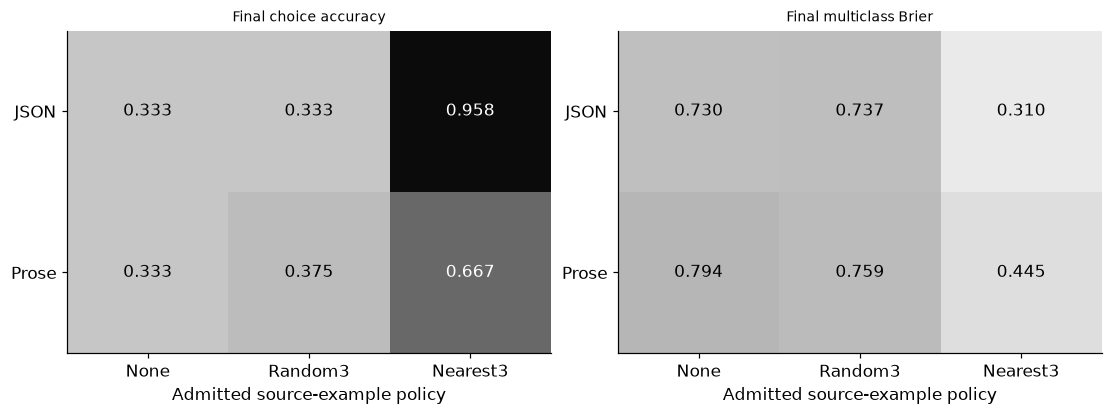

In [2]:
import os,importlib.metadata
ASSET_ROOT=next((root for root in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (root/'build/model-cache').is_dir()),Path.cwd().parent)
os.environ['HF_HUB_CACHE']=str(ASSET_ROOT/'build/model-cache');os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1';os.environ['TOKENIZERS_PARALLELISM']='false'
ASSETS={'smollm': {'repository': 'HuggingFaceTB/SmolLM2-135M-Instruct', 'revision': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'files': [{'filename': 'README.md', 'bytes': 6772, 'sha256': '4f97533ad95b1b2fea15fbc075c01b94578ebdd7c8138888fa43fa3abd530dc4', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/README.md'}, {'filename': 'config.json', 'bytes': 861, 'sha256': '8eb740e8bbe4cff95ea7b4588d17a2432deb16e8075bc5828ff7ba9be94d982a', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/config.json'}, {'filename': 'generation_config.json', 'bytes': 132, 'sha256': '87b916edaaab66b3899b9d0dd0752727dff6666686da0504d89ae0a6e055a013', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/generation_config.json'}, {'filename': 'merges.txt', 'bytes': 466391, 'sha256': '0b54e8aa4e53d5383e2e4bc635a56b43f9647f7b13832d5d9ecd8f82dac4f510', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/merges.txt'}, {'filename': 'model.safetensors', 'bytes': 269060552, 'sha256': '5af571cbf074e6d21a03528d2330792e532ca608f24ac70a143f6b369968ab8c', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/model.safetensors'}, {'filename': 'special_tokens_map.json', 'bytes': 655, 'sha256': '2b7379f3ae813529281a5c602bc5a11c1d4e0a99107aaa597fe936c1e813ca52', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/special_tokens_map.json'}, {'filename': 'tokenizer.json', 'bytes': 2104556, 'sha256': '9ca9acddb6525a194ec8ac7a87f24fbba7232a9a15ffa1af0c1224fcd888e47c', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/tokenizer.json'}, {'filename': 'tokenizer_config.json', 'bytes': 3764, 'sha256': '4ec77d44f62efeb38d7e044a1db318f6a939438425312dfa333b8382dbad98df', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/tokenizer_config.json'}, {'filename': 'vocab.json', 'bytes': 800662, 'sha256': '82b84012e3add4d01d12ba14442026e49b8cbbaead1f79ecf3d919784f82dc79', 'cache_relative_path': 'build/model-cache/models--HuggingFaceTB--SmolLM2-135M-Instruct/snapshots/12fd25f77366fa6b3b4b768ec3050bf629380bac/vocab.json'}], 'licence': 'Apache-2.0'}};MODEL_PATHS={}
for name,model in ASSETS.items():
    for file in model['files']:
        path=ASSET_ROOT/file['cache_relative_path']
        if not path.is_file():raise FileNotFoundError('Explicit model acquisition is required: build/chapter30-runtime/bin/python scripts/acquire_chapter30_models.py')
        blob=path.read_bytes();assert len(blob)==file['bytes'] and hashlib.sha256(blob).hexdigest()==file['sha256']
    MODEL_PATHS[name]=path.parents[len(Path(file['filename']).parts)-1]
print('All declared model/config/tokenizer hashes verified; inference is offline.')

from transformers import AutoTokenizer,AutoModelForCausalLM
from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar()
VERSIONS['transformers']=importlib.metadata.version('transformers')
tokenizer=AutoTokenizer.from_pretrained(MODEL_PATHS['smollm'],local_files_only=True);tokenizer.padding_side='left';tokenizer.pad_token=tokenizer.eos_token
language_model=AutoModelForCausalLM.from_pretrained(MODEL_PATHS['smollm'],local_files_only=True,dtype=torch.float32,attn_implementation='eager').eval()
LABELS=['A','B','C'];label_token_ids=[tokenizer.encode(label,add_special_tokens=False) for label in LABELS];assert all(len(ids)==1 for ids in label_token_ids);label_ids=[ids[0] for ids in label_token_ids]
def render_prompt(content):return tokenizer.apply_chat_template([{'role':'user','content':content}],tokenize=False,add_generation_prompt=True)
def candidate_probabilities(prompts,batch_size=8):
    probabilities=[];allowed_mass=[];token_counts=[]
    for start in range(0,len(prompts),batch_size):
        batch=tokenizer(prompts[start:start+batch_size],return_tensors='pt',padding=True);token_counts.extend(batch['attention_mask'].sum(1).tolist())
        with torch.no_grad():logits=language_model(**batch).logits[:,-1];p=logits[:,label_ids].softmax(-1);mass=logits.softmax(-1)[:,label_ids].sum(-1)
        probabilities.extend(p.numpy());allowed_mass.extend(mass.numpy())
    return np.array(probabilities),np.array(allowed_mass),np.array(token_counts)
RULE='Choose inspection priority from stated measurements only. A means routine: crack width below 0.15 mm, corrosion below 15 percent, and age at most 365 days. C means urgent: crack width at least 0.40 mm OR corrosion at least 15 percent. B means inspect soon: any other case. Apply C before B before A. Return exactly one letter A, B or C; no explanation.'
def make_states(n,start_id=0):
    states=[];truth=[]
    for j in range(n):
        level=j%3
        if level==0:width=rng.uniform(.01,.14);corrosion=rng.uniform(0,10);age=int(rng.integers(1,300))
        elif level==1:width=rng.uniform(.16,.39);corrosion=rng.uniform(0,10);age=int(rng.integers(1,600))
        else:width=rng.uniform(.45,.8);corrosion=rng.uniform(16,25);age=int(rng.integers(1,600))
        state={'crack_width_mm':round(float(width),2),'corrosion_percent':round(float(corrosion),1),'inspection_age_days':age};states.append(state);truth.append(2 if state['crack_width_mm']>=.4 or state['corrosion_percent']>=15 else 1 if state['crack_width_mm']>=.15 or age>365 else 0)
    return states,np.array(truth)

from sklearn.metrics import accuracy_score,log_loss
source,source_truth=make_states(45);final,final_truth=make_states(24);source_buildings=np.repeat(np.arange(15),3);final_buildings=np.repeat(np.arange(100,108),3);assert not set(source_buildings)&set(final_buildings)
fields=['crack_width_mm','corrosion_percent','inspection_age_days'];sx=np.array([[s[k] for k in fields] for s in source]);fx=np.array([[s[k] for k in fields] for s in final]);mu=sx.mean(0);scale=np.maximum(sx.std(0),1e-6);distance=np.sum(((fx[:,None]-sx[None])/scale)**2,axis=2);nearest=np.argsort(distance,axis=1)[:,:3];selection_rng=np.random.default_rng(SEED+1);random_examples=np.array([selection_rng.choice(45,3,replace=False) for _ in final]);assert nearest.shape==(24,3) and np.max(nearest)<45
def represent(state,kind):
    if kind=='JSON':return json.dumps(state,sort_keys=True)
    return f"Crack width is {state['crack_width_mm']:.2f} mm; corrosion is {state['corrosion_percent']:.1f} percent; inspection age is {state['inspection_age_days']} days."
before=parameter_digest(language_model);rows=[];outputs={};source_ids_used={}
for kind in ['JSON','Prose']:
    for policy in ['No examples','Random three','Nearest three']:
        prompts=[];admitted=[]
        for j,state in enumerate(final):
            ids=[] if policy=='No examples' else random_examples[j].tolist() if policy=='Random three' else nearest[j].tolist();admitted.extend(ids);examples=''.join('Example state: '+represent(source[i],kind)+' Answer: '+LABELS[source_truth[i]]+'\n' for i in ids);prompts.append(render_prompt(RULE+'\n'+examples+'Target state: '+represent(state,kind)))
        p,mass,tokens=candidate_probabilities(prompts);outputs[(kind,policy)]=p;source_ids_used[(kind,policy)]=sorted(set(admitted));rows.append({'representation':kind,'policy':policy,'final_accuracy':float(accuracy_score(final_truth,p.argmax(1))),'final_Brier':float(np.mean(np.sum((p-np.eye(3)[final_truth])**2,1))),'final_log_loss':float(log_loss(final_truth,p,labels=[0,1,2])),'mean_prompt_tokens':float(tokens.mean()),'examples_per_request':0 if policy=='No examples' else 3,'distinct_admitted_source_labels':len(set(admitted)),'final_labels_admitted':0})
assert before==parameter_digest(language_model)
for key,ids in source_ids_used.items():assert all(0<=i<45 for i in ids)
disagreements={policy:float(np.mean(outputs[('JSON',policy)].argmax(1)!=outputs[('Prose',policy)].argmax(1))) for policy in ['No examples','Random three','Nearest three']}
RESULTS.update(source_buildings=15,source_states=45,final_buildings=8,final_states=24,comparisons=rows,representation_disagreement=disagreements,nearest_examples=nearest.tolist(),source_only_scale=scale.tolist(),source_final_group_overlap=0,weights_unchanged=True,final_labels_admitted=0);display(pd.DataFrame(rows));print('JSON/prose decision disagreement:',disagreements)
fig,axes=plt.subplots(1,2,figsize=(10,4));policies=['No examples','Random three','Nearest three'];accuracy=np.array([[r['final_accuracy'] for r in rows if r['representation']==kind] for kind in ['JSON','Prose']]);brier=np.array([[r['final_Brier'] for r in rows if r['representation']==kind] for kind in ['JSON','Prose']])
for ax,values,title in [(axes[0],accuracy,'Final choice accuracy'),(axes[1],brier,'Final multiclass Brier')]:
    im=ax.imshow(values,cmap='Greys',vmin=0,vmax=1 if title.endswith('accuracy') else 2);ax.set(xticks=range(3),xticklabels=['None','Random3','Nearest3'],yticks=[0,1],yticklabels=['JSON','Prose'],xlabel='Admitted source-example policy',title=title)
    for (i,j),value in np.ndenumerate(values):ax.text(j,i,f'{value:.3f}',ha='center',va='center',color='white' if value>(.5 if title.endswith('accuracy') else 1) else 'black')
plt.show()


<a id="context-budget-and-adaptation"></a>
 ## Examples are supervised information even when weights are frozen
 Each source example exposes an observed outcome through context. Nearest retrieval uses numeric feature distances, not final labels, and source-only scale fitting keeps target distributions outside that transformation. Different representations can change tokenization and prediction even while their facts match. Native fine-tuning would change parameters and need additional training/development budgets; none is executed or credited here. Tool-calculated measurements could be serialized into the same state, but their numerical verification remains a separate task. These experiments do not select a winning prompt for deployment or claim that a small public checkpoint represents all instruction models.


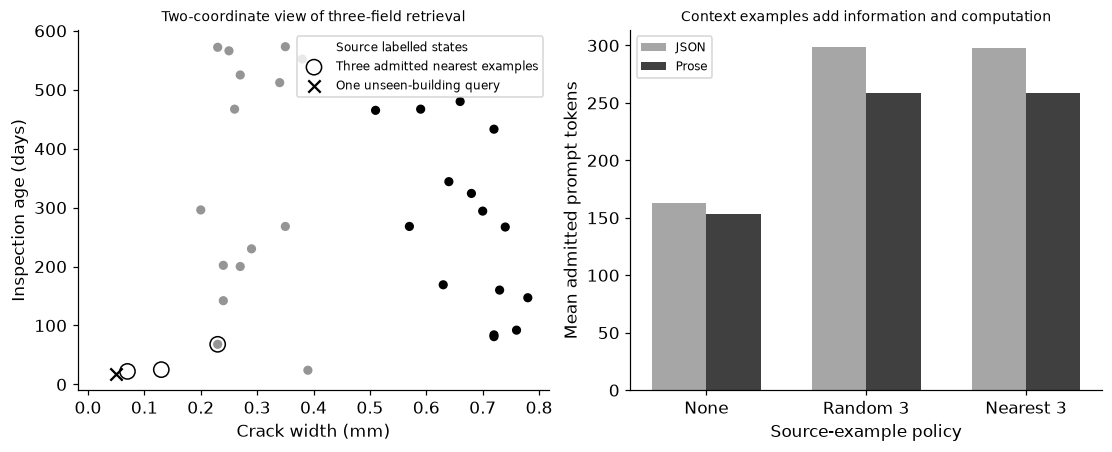

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(sx[:,0],sx[:,2],c=source_truth,cmap='Greys',vmin=0,vmax=2,s=25,label='Source labelled states');ids=nearest[0];axes[0].scatter(sx[ids,0],sx[ids,2],facecolors='none',edgecolors='black',s=100,label='Three admitted nearest examples');axes[0].scatter(fx[0,0],fx[0,2],marker='x',c='black',s=65,label='One unseen-building query');axes[0].set(xlabel='Crack width (mm)',ylabel='Inspection age (days)',title='Two-coordinate view of three-field retrieval');axes[0].legend(fontsize=8)
xx=np.arange(3);axes[1].bar(xx-.17,[r['mean_prompt_tokens'] for r in rows[:3]],width=.34,color='.65',label='JSON');axes[1].bar(xx+.17,[r['mean_prompt_tokens'] for r in rows[3:]],width=.34,color='.25',label='Prose');axes[1].set(xticks=xx,xticklabels=['None','Random 3','Nearest 3'],ylabel='Mean admitted prompt tokens',xlabel='Source-example policy',title='Context examples add information and computation');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==6 and all(r['final_labels_admitted']==0 for r in rows)


In [4]:
summary={'example_id':'code_156','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual fixed-checkpoint prompt comparison on unseen building groups', 'equivalent JSON and prose measurement representations', 'zero-example random-example and source-only nearest-example policies', 'source-fitted retrieval scale and explicit label-access audit', 'weight invariance and prompt-token budgets without native fine-tuning claims'],'results':RESULTS,'disclosed_warnings':DISCLOSED_WARNINGS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual fixed-checkpoint prompt comparison on unseen building groups", "equivalent JSON and prose measurement representations", "zero-example random-example and source-only nearest-example policies", "source-fitted retrieval scale and explicit label-access audit", "weight invariance and prompt-token budgets without native fine-tuning claims"], "disclosed_warnings": [{"category": "TqdmWarning", "message": "IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html"}], "elapsed_seconds": 17.118, "example_id": "code_156", "hardware": "Darwin arm64 CPU", "results": {"comparisons": [{"distinct_admitted_source_labels": 0, "examples_per_request": 0, "final_Brier": 0.7300341066675382, "final_accuracy": 0.3333333333333333, "final_labels_admitted": 0, "final_log_loss": 1.1887829303741455, "mean_prompt_tokens": 162.875, "policy": "No examples", "representation": "JSON"}, {"distinct_